<a href="https://colab.research.google.com/github/suriarasai/BEAD2026/blob/main/colab/rebu/02TripEnrichmentandPricing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Trip Enrichment:  Geographic, Time & Pricing Intelligence
**Business outcome:** every trip tagged with *where* (region, place type), *when* (tariff band, weekend, public holiday) and *what it should have cost*. Together these give a **pricing-compliance / revenue-leakage** view and the classic origin–destination analytics.

| # | UDF | Kind | Business question |
|---|-----|------|-------------------|
| 1 | `place_category`, `postal_geo` | Python UDF (`string`, `struct`) | Which *kinds* of places and regions generate demand? |
| 2 | `haversine_py` vs `haversine_vec` | row UDF vs **pandas UDF** | Is `Distance` odometer or straight-line? (+ a vectorisation benchmark) |
| 3 | `sg_time_context` | Python UDF → `struct` | Peak / midnight / holiday tagging driven by a tariff config |
| 4 | `make_expected_fare(tariff)` | UDF factory → `struct` | Are fares charged according to the vehicle-class tariff? |

## Setup
Run these four cells first. In Colab, you'll be asked to authorise Google Drive.

In [6]:
#@title  1 · Environment (PySpark + Java) — run once { display-mode: "form" }
import os, sys, re, glob, time, subprocess, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def _java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)(?:\.(\d+))?', out)
        major = int(m.group(1))
        return int(m.group(2)) if major == 1 else major
    except Exception:
        return None

try:
    import pyspark
except ImportError:                      # recent Colab images ship PySpark; install only if missing
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.5"], check=True)
    import pyspark

_spark_major, _jv = int(pyspark.__version__.split(".")[0]), _java_major()
# Spark 3.5 runs on Java 8/11/17, Spark 4.x on Java 17/21 → fix the JDK on Colab if they don't match
if IN_COLAB and (_jv is None or (_spark_major < 4 and _jv > 17) or (_spark_major >= 4 and _jv < 17)):
    subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

print(f"PySpark {pyspark.__version__} · Java {_java_major()} · Colab={IN_COLAB}")

PySpark 4.0.4 · Java 21 · Colab=True


In [7]:
#@title 2 · Point to the data { display-mode: "form" }
#@markdown Put the 9 CSV files (Booking, Payment, Rewards, Passengers, Drivers, Taxi, TaxiType, Place, PaymentType)
#@markdown in one Google Drive folder and set its path here. File names may carry a prefix (e.g. `2eaaf3ac-Passengers.csv`).
DATA_DIR = "/content/drive/MyDrive/rebu"  #@param {type:"string"}
TABLES = ["Booking", "Payment", "Rewards", "Passengers", "Drivers", "Taxi", "TaxiType", "Place", "PaymentType"]

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not glob.glob(os.path.join(DATA_DIR, "*.csv")):
        print(f"No CSVs in {DATA_DIR} – falling back to direct upload (Drive is faster for the ~50 MB files).")
        from google.colab import files
        DATA_DIR = "/content/data"; os.makedirs(DATA_DIR, exist_ok=True)
        for fname, blob in files.upload().items():
            with open(os.path.join(DATA_DIR, fname), "wb") as fh:
                fh.write(blob)
else:
    DATA_DIR = os.environ.get("SG_TAXI_DATA", "./data")

LAKE_DIR = os.path.join(DATA_DIR, "lakehouse")      # bronze / silver / gold outputs land here

def find_csv(name):
    """Match 'Taxi.csv' or '<prefix>-Taxi.csv' but never 'TaxiType.csv'."""
    hits = [p for p in glob.glob(os.path.join(DATA_DIR, "*.csv"))
            if re.fullmatch(rf"(?:.*[-_ ])?{name}\.csv", os.path.basename(p), flags=re.I)]
    if not hits:
        raise FileNotFoundError(f"{name}.csv not found in {DATA_DIR}")
    return hits[0]

for t in TABLES:
    print(f"{t:<12} → {os.path.basename(find_csv(t))}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Booking      → Booking.csv
Payment      → Payment.csv
Rewards      → Rewards.csv
Passengers   → Passengers.csv
Drivers      → Drivers.csv
Taxi         → Taxi.csv
TaxiType     → TaxiType.csv
Place        → Place.csv
PaymentType  → PaymentType.csv


In [8]:
#@title 3 · Spark session, readers & chart style { display-mode: "form" }
from pyspark.sql import SparkSession, Window, functions as F, types as T
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from IPython.display import display, Markdown

# --add-opens lets Arrow (used by pandas UDFs) work on newer JDKs; harmless on Java 11
_JOPTS = " ".join(f"--add-opens=java.base/{p}=ALL-UNNAMED"
                  for p in ["java.nio", "sun.nio.ch", "java.lang", "java.util"]) + " -Dio.netty.tryReflectionSetAccessible=true"
spark = (SparkSession.builder.appName("SG-Taxi-BI-UDFs").master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "Asia/Singapore")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .config("spark.driver.extraJavaOptions", _JOPTS)
         .config("spark.executor.extraJavaOptions", _JOPTS)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def read_csv(name):
    """Bronze read: every column as a raw string, delimiter sniffed (Booking.csv is tab-separated)."""
    path = find_csv(name)
    with open(path, encoding="utf-8-sig") as fh:
        header = fh.readline()
    sep = "\t" if header.count("\t") > header.count(",") else ","
    return spark.read.csv(path, header=True, sep=sep, inferSchema=False, quote='"', escape='"')

def show(df, n=10):
    """Pretty table in Colab (Spark → pandas for display only)."""
    display(df.limit(n).toPandas())

def timed(label, df):
    """Force full evaluation without collecting (noop sink) and time it."""
    t0 = time.perf_counter()
    df.write.format("noop").mode("overwrite").save()
    secs = time.perf_counter() - t0
    print(f"{label:<48}{secs:7.2f} s")
    return secs

# Chart style: thin marks, recessive grid, fixed categorical order, single-hue sequential ramp
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
mpl.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10, "axes.axisbelow": True,
})
print("Spark", spark.version, "ready")

Spark 4.0.4 ready


In [9]:
#@title 4 · Load conformed tables (typed, timestamps parsed) { display-mode: "form" }
#@markdown Notebook 01 shows how these were cleansed; here we just apply the same typing so this notebook runs standalone.
raw = {t: read_csv(t) for t in TABLES}
TS_FMT = "d/M/yyyy H:mm"                                   # Booking.csv uses day-first dates

bookings = raw["Booking"].select(
    *[F.col(c).cast("int").alias(c) for c in ["BookingID", "PassengerID", "DriverID", "TaxiID", "PickupPlaceID", "DropoffPlaceID"]],
    F.to_timestamp("BookingDateTime", TS_FMT).alias("BookingTS"),
    F.to_timestamp("PickupTime", TS_FMT).alias("PickupTS"),
    F.to_timestamp("DropoffTime", TS_FMT).alias("DropoffTS"),
    F.col("Distance").cast("double").alias("DistanceKm"),
    F.col("Fare").cast("double").alias("Fare"),
    F.col("Status").alias("BookingStatus"),
).cache()

payments = raw["Payment"].select(
    *[F.col(c).cast("int").alias(c) for c in ["PaymentID", "BookingID", "PaymentTypeID"]],
    F.col("Amount").cast("double").alias("Amount"),
    F.to_timestamp("PaymentDateTime").alias("PaymentTS"),
    F.col("Status").alias("PaymentStatus"),
).cache()

rewards = raw["Rewards"].select(
    *[F.col(c).cast("int").alias(c) for c in ["RewardID", "PassengerID", "Points"]],
    F.to_date("EarnedDate").alias("EarnedDate"), "Description",
    F.regexp_extract("Description", r"#(\d+)", 1).cast("int").alias("BookingID"),
).cache()

passengers = raw["Passengers"].select(
    F.col("PassengerID").cast("int").alias("PassengerID"), "FirstName", "LastName", "Phone", "Email",
    "MemberCategory", F.col("Age").cast("int").alias("Age"), "Gender", "Address",
    F.to_date("RegistrationDate").alias("RegistrationDate"),
).cache()

drivers = raw["Drivers"].select(
    F.col("DriverID").cast("int").alias("DriverID"), "FirstName", "LastName", "Phone", "Email", "LicenseNumber",
    F.col("Age").cast("int").alias("Age"), "Gender", F.col("YearsExperience").cast("int").alias("YearsExperience"),
    F.col("Rating").cast("double").alias("Rating"), F.to_date("JoinDate").alias("JoinDate"),
).cache()

taxis = raw["Taxi"].select(
    F.col("TaxiID").cast("int").alias("TaxiID"), "LicensePlate", F.col("TaxiTypeID").cast("int").alias("TaxiTypeID"),
    "Model", F.col("YearManufactured").cast("int").alias("YearManufactured"), F.col("Status").alias("TaxiStatus"),
)
taxi_types = raw["TaxiType"].select(
    F.col("TaxiTypeID").cast("int").alias("TaxiTypeID"), F.col("TypeName").alias("TaxiType"),
    F.col("BaseFare").cast("double").alias("BaseFare"), F.col("PerKmRate").cast("double").alias("PerKmRate"),
    F.col("Capacity").cast("int").alias("Capacity"),
)
places = raw["Place"].select(
    F.col("PlaceID").cast("int").alias("PlaceID"), "PlaceName",
    F.col("Latitude").cast("double").alias("Lat"), F.col("Longitude").cast("double").alias("Lon"),
    F.lpad("PostalCode", 6, "0").alias("PostalCode"),
)
payment_types = raw["PaymentType"].select(F.col("PaymentTypeID").cast("int").alias("PaymentTypeID"),
                                          F.col("TypeName").alias("PaymentMethod"))

for name, df in [("bookings", bookings), ("payments", payments), ("rewards", rewards), ("passengers", passengers),
                 ("drivers", drivers), ("taxis", taxis), ("places", places)]:
    print(f"{name:<11}{df.count():>10,} rows")

bookings      505,630 rows
payments      962,068 rows
rewards       931,164 rows
passengers      1,000 rows
drivers           400 rows
taxis             400 rows
places             87 rows


In [10]:
#@title 5 · Singapore reference: postal sectors → districts → regions, place categories { display-mode: "form" }
# URA postal districts: first two digits of a 6-digit postcode ("sector") identify the district (1–28).
_DISTRICT_SECTORS = {1: "01 02 03 04 05 06", 2: "07 08", 3: "14 15 16", 4: "09 10", 5: "11 12 13", 6: "17",
                     7: "18 19", 8: "20 21", 9: "22 23", 10: "24 25 26 27", 11: "28 29 30", 12: "31 32 33",
                     13: "34 35 36 37", 14: "38 39 40 41", 15: "42 43 44 45", 16: "46 47 48", 17: "49 50 81",
                     18: "51 52", 19: "53 54 55 82", 20: "56 57", 21: "58 59", 22: "60 61 62 63 64",
                     23: "65 66 67 68", 24: "69 70 71", 25: "72 73", 26: "77 78", 27: "75 76", 28: "79 80"}
SECTOR_TO_DISTRICT = {s: d for d, secs in _DISTRICT_SECTORS.items() for s in secs.split()}
# Approximate grouping of districts into the five planning regions (good enough for BI roll-ups)
DISTRICT_TO_REGION = {**{d: "Central" for d in (1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13)},
                      **{d: "East" for d in (14, 15, 16, 17, 18)},
                      **{d: "West" for d in (5, 21, 22, 23, 24)},
                      **{d: "North" for d in (25, 26, 27)},
                      **{d: "North-East" for d in (19, 20, 28)}}
REGIONS = ["Central", "East", "North-East", "North", "West"]

# Ordered keyword rules → first match wins
PLACE_CATEGORY_RULES = [
    ("Airport",               r"airport"),
    ("Hospital",              r"hospital"),
    ("University",            r"^(nus|ntu|smu|sutd)$"),
    ("Business / Industrial", r"business park|industrial|science park|one-north|jurong island"),
    ("Attraction",            r"sentosa|gardens|zoo|universal|safari|bird park|esplanade|merlion|fort canning|marina bay sands|clarke quay"),
    ("Mall",                  r"vivocity|ion orchard|ngee ann|suntec|junction|plaza singapura|funan|^imm$|^jem$|westgate|orchard road"),
    ("CBD",                   r"raffles place|city hall|chinatown|tanjong pagar"),
]

geo_schema = T.StructType([T.StructField("postal_district", T.IntegerType()),
                           T.StructField("region", T.StringType()),
                           T.StructField("postal_valid", T.BooleanType())])

@F.udf(geo_schema)
def postal_geo(postal):
    """6-digit SG postcode → (district, region, valid?)."""
    if not postal or not re.fullmatch(r"\d{6}", postal.strip()):
        return (None, None, False)
    d = SECTOR_TO_DISTRICT.get(postal.strip()[:2])
    return (d, DISTRICT_TO_REGION.get(d), d is not None)

@F.udf("string")
def place_category(name):
    """Keyword classifier for points of interest."""
    n = (name or "").strip().lower()
    for label, pattern in PLACE_CATEGORY_RULES:
        if re.search(pattern, n):
            return label
    return "Town / MRT hub"

In [11]:
#@title 6 ·  Singapore calendar & tariff rules { display-mode: "form" }
from datetime import date, datetime, timedelta
# Gazetted public holidays incl. observed Mondays (2023 – Jan 2025)
SG_PUBLIC_HOLIDAYS = {
    "2023-01-01": "New Year's Day", "2023-01-02": "New Year's Day (obs)", "2023-01-22": "Chinese New Year",
    "2023-01-23": "Chinese New Year", "2023-01-24": "Chinese New Year (obs)", "2023-04-07": "Good Friday",
    "2023-04-22": "Hari Raya Puasa", "2023-05-01": "Labour Day", "2023-06-02": "Vesak Day",
    "2023-06-29": "Hari Raya Haji", "2023-08-09": "National Day", "2023-09-01": "Polling Day",
    "2023-11-12": "Deepavali", "2023-11-13": "Deepavali (obs)", "2023-12-25": "Christmas Day",
    "2024-01-01": "New Year's Day", "2024-02-10": "Chinese New Year", "2024-02-11": "Chinese New Year",
    "2024-02-12": "Chinese New Year (obs)", "2024-03-29": "Good Friday", "2024-04-10": "Hari Raya Puasa",
    "2024-05-01": "Labour Day", "2024-05-22": "Vesak Day", "2024-06-17": "Hari Raya Haji",
    "2024-08-09": "National Day", "2024-10-31": "Deepavali", "2024-12-25": "Christmas Day",
    "2025-01-01": "New Year's Day",
}
# Surcharge bands keyed on booking hour — reverse-engineered from this dataset (see notebook 02).
# Swap in the operator's official tariff here and every downstream UDF picks it up.
SURCHARGE_RULES = [  # (start_hour, end_hour_exclusive, band, multiplier)
    (0, 7, "Midnight", 1.50),
    (7, 10, "Morning Peak", 1.25),
    (17, 21, "Evening Peak", 1.25),
]
DEFAULT_BAND = ("Off-Peak", 1.00)

def band_for_hour(h):
    for lo, hi, band, mult in SURCHARGE_RULES:
        if lo <= h < hi:
            return band, mult
    return DEFAULT_BAND

### 6.1 Place dimension (category & region UDFs)

In [12]:
dim_place = (places
    .withColumn("Category", place_category("PlaceName"))
    .withColumn("geo", postal_geo("PostalCode"))
    .select("PlaceID", "PlaceName", "Category", "geo.region", "geo.postal_district", "PostalCode", "Lat", "Lon")
    .withColumnRenamed("region", "Region").withColumnRenamed("postal_district", "District")
    .cache())
show(dim_place, 12)
show(dim_place.groupBy("Category").pivot("Region", REGIONS).count().fillna(0).orderBy("Category"), 10)

,PlaceID,PlaceName,Category,Region,District,PostalCode,Lat,Lon
0,1,Orchard Road,Mall,Central,9,238859,1.3048,103.8318
1,2,Marina Bay Sands,Attraction,Central,1,018956,1.2834,103.8607
2,3,Raffles Place,CBD,Central,1,048616,1.2844,103.8510
3,4,Clarke Quay,Attraction,Central,6,179024,1.2895,103.8467
4,5,Bugis,Town / MRT hub,Central,7,188021,1.3000,103.8560
5,6,City Hall,CBD,Central,6,178957,1.2930,103.8520
6,7,Chinatown,CBD,Central,1,058357,1.2830,103.8440
7,8,Little India,Town / MRT hub,Central,8,217555,1.3065,103.8520
8,9,Dhoby Ghaut,Town / MRT hub,Central,9,238895,1.2990,103.8460
9,10,Somerset,Town / MRT hub,Central,9,238859,1.3008,103.8390


,Category,Central,East,North-East,North,West
0,Airport,0,1,0,0,0
1,Attraction,9,0,0,2,1
2,Business / Industrial,0,1,0,0,4
3,CBD,3,0,0,0,0
4,Hospital,2,1,0,0,1
5,Mall,8,0,0,0,3
6,Town / MRT hub,10,11,9,7,10
7,University,1,1,0,0,2


### 6.2 · Haversine distance — row UDF vs pandas UDF
Join pickup and drop-off coordinates (a broadcast join, since `places` is tiny), then compute great-circle distance two ways.

In [13]:
import math
R_KM = 6371.0088

@F.udf("double")
def haversine_py(lat1, lon1, lat2, lon2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi, dlmb = p2 - p1, math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlmb / 2) ** 2
    return 2 * R_KM * math.asin(math.sqrt(a))

@F.pandas_udf("double")
def haversine_vec(lat1: pd.Series, lon1: pd.Series, lat2: pd.Series, lon2: pd.Series) -> pd.Series:
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R_KM * np.arcsin(np.sqrt(a))

pu = dim_place.select(F.col("PlaceID").alias("PickupPlaceID"), F.col("PlaceName").alias("PickupPlace"),
                      F.col("Category").alias("PickupCategory"), F.col("Region").alias("PickupRegion"),
                      F.col("Lat").alias("pu_lat"), F.col("Lon").alias("pu_lon"))
do = dim_place.select(F.col("PlaceID").alias("DropoffPlaceID"), F.col("PlaceName").alias("DropoffPlace"),
                      F.col("Category").alias("DropoffCategory"), F.col("Region").alias("DropoffRegion"),
                      F.col("Lat").alias("do_lat"), F.col("Lon").alias("do_lon"))
trips = bookings.join(F.broadcast(pu), "PickupPlaceID").join(F.broadcast(do), "DropoffPlaceID").cache()
trips.count()

args = ["pu_lat", "pu_lon", "do_lat", "do_lon"]
t_row = timed("Row-at-a-time Python UDF", trips.select(haversine_py(*args)))
t_vec = timed("Vectorised pandas UDF (Arrow batches)", trips.select(haversine_vec(*args)))
print(f"→ pandas UDF ~{t_row / max(t_vec, 1e-6):.1f}× faster")

Row-at-a-time Python UDF                           3.42 s
Vectorised pandas UDF (Arrow batches)              3.96 s
→ pandas UDF ~0.9× faster


In [14]:
chk = trips.withColumn("hav_km", haversine_vec(*args)).filter("hav_km > 0")
show(chk.select(F.corr("DistanceKm", "hav_km").alias("correlation"),
                F.expr("percentile_approx(DistanceKm / hav_km, array(0.01, 0.5, 0.99))").alias("ratio_p01_p50_p99")))

,correlation,ratio_p01_p50_p99
0,1.0,"[0.9971919642654506, 0.9999856699927177, 1.002..."


**Finding:** recorded `Distance` equals the **straight-line** distance between places (correlation 1.0, ratio ≈ 1.00). It isn't odometer distance. Real road distance in Singapore is typically 20–40% longer, so per-km revenue and per-km emissions computed from this field are **overstated per actual km**. Label it clearly in the semantic layer (`DistanceKm (straight-line)`).

### 6.3 · Time intelligence — discovering the tariff, then encoding it in a UDF
Before writing a surcharge UDF, let the data show the tariff. Median **fare per km** for mid-length trips (8–16 km), by booking hour:

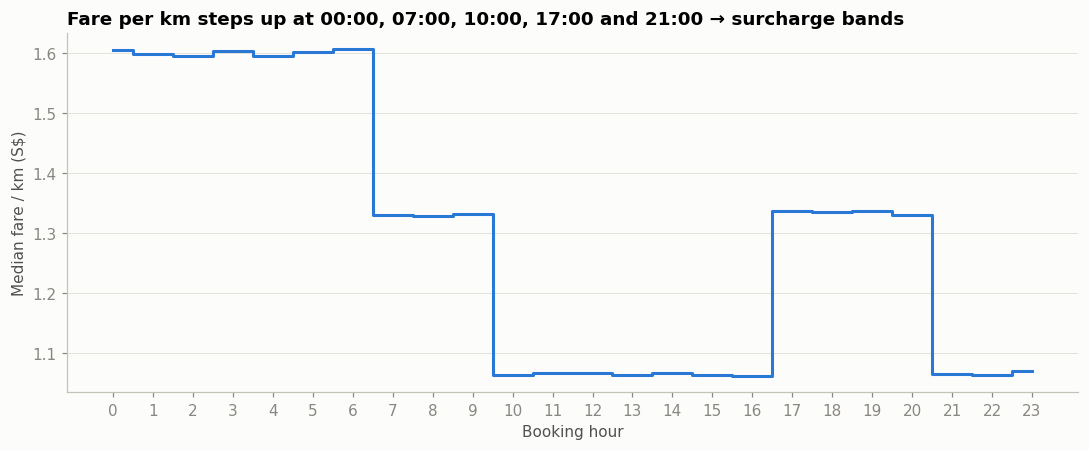

In [15]:
hourly = (bookings.filter("DistanceKm BETWEEN 8 AND 16")
          .groupBy(F.hour("BookingTS").alias("hour"))
          .agg(F.expr("percentile_approx(Fare / DistanceKm, 0.5)").alias("median_fare_per_km"), F.count("*").alias("trips"))
          .orderBy("hour").toPandas())
fig, ax = plt.subplots()
ax.step(hourly["hour"], hourly["median_fare_per_km"], where="mid", color=PALETTE[0])
ax.set_xticks(range(0, 24)); ax.set_xlabel("Booking hour"); ax.set_ylabel("Median fare / km (S$)")
ax.set_title("Fare per km steps up at 00:00, 07:00, 10:00, 17:00 and 21:00 → surcharge bands")
plt.tight_layout(); plt.show()

Three plateaus: **×1.5 from 00:00–06:59**, **×1.25 from 07:00–09:59 and 17:00–20:59**, **×1.0** otherwise. Those are the `SURCHARGE_RULES` in the calendar cell above. *(They differ from the published LTA street-hail schedule, so treat them as this operator's tariff.)* The UDF below reads that config, so finance can change bands without touching code.

In [16]:
time_schema = T.StructType([T.StructField(n, t) for n, t in [
    ("time_band", T.StringType()), ("surcharge_mult", T.DoubleType()), ("day_type", T.StringType()),
    ("is_public_holiday", T.BooleanType()), ("holiday_name", T.StringType()), ("day_part", T.StringType())]])

@F.udf(time_schema)
def sg_time_context(ts):
    if ts is None:
        return None
    band, mult = band_for_hour(ts.hour)
    hol = SG_PUBLIC_HOLIDAYS.get(ts.strftime("%Y-%m-%d"))
    day_type = "Public Holiday" if hol else ("Weekend" if ts.weekday() >= 5 else "Weekday")
    day_part = ("Late night" if ts.hour < 5 else "Morning" if ts.hour < 12 else
                "Afternoon" if ts.hour < 17 else "Evening" if ts.hour < 21 else "Night")
    return (band, mult, day_type, hol is not None, hol, day_part)

trips = trips.withColumn("tc", sg_time_context("BookingTS")).select("*", "tc.*").drop("tc").cache()
show(trips.groupBy("time_band", "surcharge_mult").agg(F.count("*").alias("trips"), F.round(F.avg("Fare"), 2).alias("avg_fare"))
          .orderBy("surcharge_mult"))
show(trips.groupBy("day_type").agg(F.count("*").alias("trips"), F.countDistinct(F.to_date("BookingTS")).alias("days"))
          .withColumn("trips_per_day", F.round(F.col("trips") / F.col("days"), 1)))

,time_band,surcharge_mult,trips,avg_fare
0,Off-Peak,1.00,210300,16.72
1,Morning Peak,1.25,63304,14.48
2,Evening Peak,1.25,84418,20.07
3,Midnight,1.50,147608,14.32


,day_type,trips,days,trips_per_day
0,Weekday,345931,618,559.8
1,Weekend,140742,310,454.0
2,Public Holiday,18957,50,379.1


### 6.4 · Pricing compliance — expected fare vs actual fare
`TaxiType` publishes a **flag-down + per-km tariff** per vehicle class. The UDF factory below closes over that tariff table (collected once, since it's tiny) and computes what each trip *should* have cost:

`expected = (BaseFare + PerKmRate × km) × surcharge_mult`

In [17]:
TARIFF = {r["TaxiTypeID"]: (r["TaxiType"], r["BaseFare"], r["PerKmRate"]) for r in taxi_types.collect()}
print("Tariff table:", TARIFF)

fare_schema = T.StructType([T.StructField("expected_fare", T.DoubleType()), T.StructField("tariff_class", T.StringType())])

def make_expected_fare(tariff):
    @F.udf(fare_schema)
    def expected_fare(taxi_type_id, km, ts):
        if taxi_type_id not in tariff or km is None or ts is None:
            return (None, None)
        name, base, per_km = tariff[taxi_type_id]
        _, mult = band_for_hour(ts.hour)
        return (round((base + per_km * km) * mult, 2), name)
    return expected_fare

expected_fare = make_expected_fare(TARIFF)

priced = (trips.filter("BookingStatus = 'Completed'")
          .join(F.broadcast(taxis.select("TaxiID", "TaxiTypeID")), "TaxiID")
          .withColumn("ef", expected_fare("TaxiTypeID", "DistanceKm", "BookingTS")).select("*", "ef.*").drop("ef")
          .withColumn("fare_gap", F.col("Fare") - F.col("expected_fare"))
          .cache())

by_class = (priced.groupBy("tariff_class")
    .agg(F.count("*").alias("trips"), F.round(F.sum("Fare"), 0).alias("actual_rev"),
         F.round(F.sum("expected_fare"), 0).alias("tariff_rev"), F.round(F.sum("fare_gap"), 0).alias("gap"),
         F.round(F.avg("Fare") / F.avg("DistanceKm"), 3).alias("actual_per_km"))
    .withColumn("gap_pct", F.round(F.col("gap") / F.col("tariff_rev") * 100, 1))
    .orderBy("gap_pct"))
show(by_class)

Tariff table: {1: ('Standard', 3.9, 0.55), 2: ('Premier', 5.0, 0.65), 3: ('Limo', 8.0, 0.85), 4: ('6-Seater', 5.5, 0.7), 5: ('Wheelchair Accessible', 4.5, 0.6)}


,tariff_class,trips,actual_rev,tariff_rev,gap,actual_per_km,gap_pct
0,Limo,100005,1638123.0,2216851.0,-578728.0,1.369,-26.1
1,6-Seater,78103,1299877.0,1315809.0,-15933.0,1.399,-1.2
2,Premier,94866,1568947.0,1473550.0,95396.0,1.387,6.5
3,Wheelchair Accessible,99444,1589136.0,1411120.0,178015.0,1.341,12.6
4,Standard,108111,1735298.0,1379870.0,355428.0,1.345,25.8


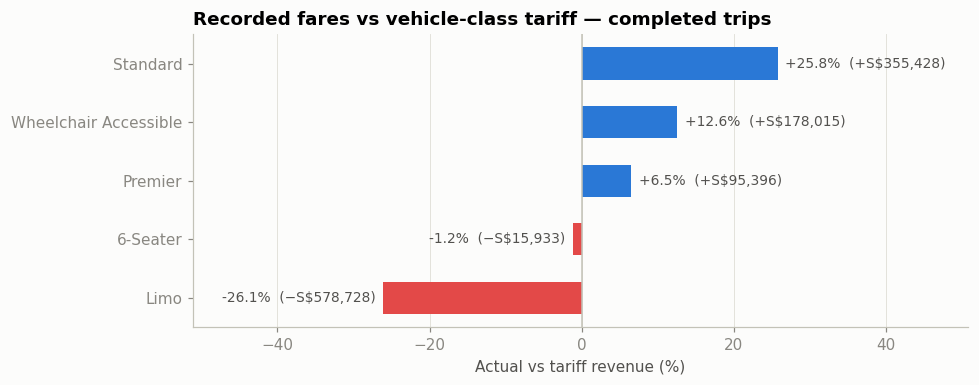

,tariff_class,fitted_per_km,fitted_flagdown,BaseFare,PerKmRate
0,6-Seater,0.846,7.01,5.5,0.70
1,Wheelchair Accessible,0.822,6.56,4.5,0.60
2,Limo,0.841,6.75,8.0,0.85
3,Premier,0.843,6.93,5.0,0.65
4,Standard,0.832,6.55,3.9,0.55


In [18]:
pc = by_class.toPandas()
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#e34948" if v < 0 else "#2a78d6" for v in pc["gap_pct"]]
ax.barh(pc["tariff_class"], pc["gap_pct"], color=colors, height=0.55)
ax.axvline(0, color="#c3c2b7", lw=1)
for y, (v, g) in enumerate(zip(pc["gap_pct"], pc["gap"])):
    ax.text(v + (1 if v >= 0 else -1), y, f"{v:+.1f}%  ({'+' if g >= 0 else '−'}S${abs(g):,.0f})", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.set_xlabel("Actual vs tariff revenue (%)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Recorded fares vs vehicle-class tariff — completed trips")
ax.set_xlim(pc["gap_pct"].min() - 25, pc["gap_pct"].max() + 25)
plt.tight_layout(); plt.show()

# Does vehicle class change the fare at all? Fit fare ≈ a + b·km per class on off-peak trips.
fit = (priced.filter("surcharge_mult = 1.0").groupBy("tariff_class")
       .agg(F.round(F.covar_samp("DistanceKm", "Fare") / F.var_samp("DistanceKm"), 3).alias("fitted_per_km"),
            F.round(F.avg("Fare") - F.covar_samp("DistanceKm", "Fare") / F.var_samp("DistanceKm") * F.avg("DistanceKm"), 2).alias("fitted_flagdown"))
       .join(taxi_types.select(F.col("TaxiType").alias("tariff_class"), "BaseFare", "PerKmRate"), "tariff_class"))
show(fit)

> Note: **Finding: fares are vehicle-class-blind.** Fitted per-km rates and flag-downs are almost identical for every class, while the published tariff ranges from S$0.55/km (Standard) to S$0.85/km (Limo).
> * **Standard & Wheelchair-Accessible** passengers pay **above** their tariff, a customer-trust and regulatory-pricing risk.
> * **Limo** trips recover **below** tariff, which is revenue leakage on the premium fleet.
>
> **Action:** check whether the booking app is applying the vehicle-class tariff at all, or whether everything is billed as a single class. The `expected_fare` UDF can sit in the pipeline as a nightly **pricing-compliance check**.

### 6.5 · BI views for origin/destination, routes, airport

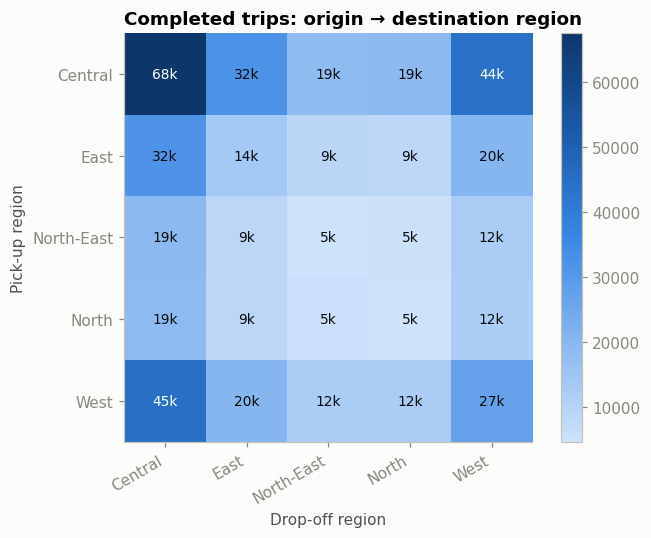

In [19]:
done = trips.filter("BookingStatus = 'Completed'")
od = (done.groupBy("PickupRegion").pivot("DropoffRegion", REGIONS).count().fillna(0)
          .toPandas().set_index("PickupRegion").reindex(REGIONS)[REGIONS])
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(od.values, cmap=SEQ)
ax.set_xticks(range(5), REGIONS, rotation=30, ha="right"); ax.set_yticks(range(5), REGIONS)
for i in range(5):
    for j in range(5):
        v = od.values[i, j]
        ax.text(j, i, f"{v/1000:.0f}k", ha="center", va="center", fontsize=9,
                color="white" if v > od.values.max() * 0.55 else "#0b0b0b")
ax.set_xlabel("Drop-off region"); ax.set_ylabel("Pick-up region"); ax.grid(False)
ax.set_title("Completed trips: origin → destination region"); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.show()

In [20]:
show(done.groupBy("PickupPlace", "DropoffPlace")
         .agg(F.count("*").alias("trips"), F.round(F.sum("Fare"), 0).alias("revenue"), F.round(F.avg("DistanceKm"), 1).alias("avg_km"))
         .orderBy(F.desc("revenue")), 10)

airport = (done.withColumn("airport_trip", (F.col("PickupCategory") == "Airport") | (F.col("DropoffCategory") == "Airport"))
           .groupBy("airport_trip").agg(F.count("*").alias("trips"), F.round(F.avg("Fare"), 2).alias("avg_fare"),
                                         F.round(F.avg("DistanceKm"), 1).alias("avg_km"), F.round(F.sum("Fare"), 0).alias("revenue")))
total_rev = done.agg(F.sum("Fare")).first()[0]
show(airport.withColumn("revenue_share_pct", F.round(F.col("revenue") / total_rev * 100, 1)))

,PickupPlace,DropoffPlace,trips,revenue,avg_km
0,Tuas,Pasir Ris,84,2909.0,33.7
1,Tuas Industrial Estate,Expo,81,2862.0,34.8
2,Joo Koon,Changi Airport,72,2761.0,35.0
3,Tuas Industrial Estate,Pasir Ris,79,2741.0,33.7
4,Expo,Joo Koon,83,2736.0,31.5
5,Changi Airport,Tuas Industrial Estate,72,2734.0,38.4
6,Tanah Merah,Tuas,76,2708.0,33.0
7,Tuas,Changi Airport,72,2708.0,38.4
8,Tuas,Simei,80,2597.0,33.9
9,Boon Lay,Changi Airport,79,2592.0,31.9


,airport_trip,trips,avg_fare,avg_km,revenue,revenue_share_pct
0,True,11255,22.40,19.4,252146.0,3.2
1,False,469274,16.15,11.7,7579234.0,96.8


In [21]:
cat_band = (done.groupBy("PickupCategory").pivot("time_band", ["Midnight", "Morning Peak", "Off-Peak", "Evening Peak"])
                .agg(F.round(F.avg("Fare"), 2)).orderBy("PickupCategory"))
print("Average fare by pickup category × tariff band (S$)")
show(cat_band, 10)

Average fare by pickup category × tariff band (S$)


,PickupCategory,Midnight,Morning Peak,Off-Peak,Evening Peak
0,Airport,19.51,19.89,22.68,27.69
1,Attraction,13.45,13.69,15.69,18.77
2,Business / Industrial,16.49,16.60,19.31,23.26
3,CBD,12.34,12.50,14.51,17.33
4,Hospital,13.41,13.85,15.66,18.82
5,Mall,12.86,13.09,15.01,18.00
6,Town / MRT hub,14.66,14.77,17.10,20.53
7,University,15.39,15.52,17.92,21.28



### 7 · Save the enriched fact table (gold) { display-mode: "form" }


In [22]:
GOLD = os.path.join(LAKE_DIR, "gold")
fact_trip_enriched = (trips.join(priced.select("BookingID", "TaxiTypeID", "tariff_class", "expected_fare", "fare_gap"), "BookingID", "left")
    .drop("pu_lat", "pu_lon", "do_lat", "do_lon"))
fact_trip_enriched.write.mode("overwrite").parquet(f"{GOLD}/fact_trip_enriched")
dim_place.write.mode("overwrite").parquet(f"{GOLD}/dim_place")
print(f"Wrote {fact_trip_enriched.count():,} enriched trips →", f"{GOLD}/fact_trip_enriched")
print("Columns:", ", ".join(fact_trip_enriched.columns))

Wrote 505,630 enriched trips → /content/drive/MyDrive/rebu/lakehouse/gold/fact_trip_enriched
Columns: BookingID, DropoffPlaceID, PickupPlaceID, PassengerID, DriverID, TaxiID, BookingTS, PickupTS, DropoffTS, DistanceKm, Fare, BookingStatus, PickupPlace, PickupCategory, PickupRegion, DropoffPlace, DropoffCategory, DropoffRegion, time_band, surcharge_mult, day_type, is_public_holiday, holiday_name, day_part, TaxiTypeID, tariff_class, expected_fare, fare_gap


## Summary
* **Distance is straight-line**, not driven km. Label it in the semantic layer.
* **Surcharge bands recovered from data** and encoded in a config-driven UDF (`sg_time_context`), with weekend and public-holiday flags.
* **Pricing compliance:** recorded fares ignore vehicle class. Standard is over-charged against tariff and Limo is under-recovered.
* Pandas UDFs beat row UDFs for numeric work. Use them whenever logic is vectorisable.

**Next:** `03CustomerIntelligence.ipynb` covers RFM, behavioural personas and loyalty reconciliation.